# **Doctoral Program in Deep Tech, Artificial Intelligence & Emerging Technologies**
## **Course:** Research Methods and Scientific Integrity in AI and Advanced Technologies
## **Instructor:** Dr. Loveleen Gaur
## **Student:** Jesús Vicente Inca Cárdenas
## **Term:** 2026-II
---
# **Deliverable 7: MODEL CARD & DATASET DATASHEET — VeriClause-HITL v0.0 (verifiable clause recommendation for regulated fiduciary institutions)**

# Session 7: Benchmarking, Ablation Studies & Reporting Standards

**Data choice.** Exercises 1–3 and 7–10 use the public **LEDGAR clause-type subset** built and versioned in Deliverable No. 5 (3,000 contract provisions, 20 clause types, MD5 `bc995ef9bacb814a07d06dbecad47ad0`) instead of the workshop dataset, so that every exercise speaks to contract clauses.

**Integrity boundary.** LEDGAR is a public English-language proxy. Its results are **course demonstrations on a proxy task**, not results of the doctoral artefact. Exercises 4–6 and 11–12 document the artefact itself, which has not yet been built or evaluated; no thesis metric is invented.

## 0 · Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, hashlib
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score

RANDOM_STATE = 42
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

# LEDGAR subset versioned with DVC in Deliverable 5 (run `dvc pull` in 05_Reproducible_ML_Pipeline first)
candidates = [Path("../05_Reproducible_ML_Pipeline/data/ledgar_subset.csv"), Path("ledgar_subset.csv")]
DATA = next(p for p in candidates if p.exists())
df = pd.read_csv(DATA)
X, y = df["text"].values, df["label_name"].values
print("Data file:", DATA, "| MD5:", hashlib.md5(DATA.read_bytes()).hexdigest())
print(f"Clauses: {len(df)} | Clause types: {df.label_name.nunique()} | per type: {df.label_name.value_counts().min()}")

def macro_f1(model, Xte, yte):
    return f1_score(yte, model.predict(Xte), average="macro")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)}  Test: {len(X_test)}")

Data file: ledgar_subset.csv | MD5: bc995ef9bacb814a07d06dbecad47ad0
Clauses: 3000 | Clause types: 20 | per type: 150
Train: 2250  Test: 750


## Exercise 1 · The weak-baseline illusion
A "fancy" model (TF-IDF word 1–2 grams + linear SVM) against a logistic-regression baseline that is first left **untuned** (C = 0.001) and then tuned **as hard as the fancy model**. In the thesis the same rule applies to B1 (standard RAG): the baseline must receive the same care as the proposed artefact.

In [2]:
fancy = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LinearSVC(C=0.5, random_state=RANDOM_STATE))
fancy.fit(X_train, y_train); f1_fancy = macro_f1(fancy, X_test, y_test)

weak = make_pipeline(TfidfVectorizer(), LogisticRegression(C=0.001, max_iter=2000, random_state=RANDOM_STATE))
weak.fit(X_train, y_train); f1_weak = macro_f1(weak, X_test, y_test)

print(f"Fancy model (TF-IDF 1-2g + LinearSVC)   macro-F1: {f1_fancy:.4f}")
print(f"UNTUNED baseline (LogReg, C=0.001)      macro-F1: {f1_weak:.4f}")
print(f"Apparent improvement over weak baseline:          {f1_fancy - f1_weak:+.4f}  <-- looks impressive!")

Fancy model (TF-IDF 1-2g + LinearSVC)   macro-F1: 0.9199
UNTUNED baseline (LogReg, C=0.001)      macro-F1: 0.7197
Apparent improvement over weak baseline:          +0.2002  <-- looks impressive!


In [3]:
strong = GridSearchCV(make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
                      {"logisticregression__C": np.logspace(-2, 2, 9)}, cv=5, scoring="f1_macro", n_jobs=1)
strong.fit(X_train, y_train); f1_strong = macro_f1(strong, X_test, y_test)
best_C = strong.best_params_["logisticregression__C"]
print(f"Fancy model                             macro-F1: {f1_fancy:.4f}")
print(f"TUNED baseline (best C={best_C:.3g})            macro-F1: {f1_strong:.4f}")
print(f"HONEST improvement over tuned baseline:            {f1_fancy - f1_strong:+.4f}")

Fancy model                             macro-F1: 0.9199
TUNED baseline (best C=100)            macro-F1: 0.9119
HONEST improvement over tuned baseline:            +0.0080


**🧪 Analysis.** Almost all of the apparent gain disappears once the baseline is tuned with the same effort. For the thesis this is the strongest argument for treating B1 (standard RAG) as a serious comparator — same base model, same knowledge-base snapshot, same retrieval budget — rather than a straw man.

## Exercise 2 · One seed is not a result
The fancy model over **10 seeds** (different stratified splits).

Per-seed macro-F1: [0.9258 0.9278 0.9313 0.9284 0.9308 0.9204 0.9267 0.9388 0.9241 0.9218]
Mean ± std : 0.9276 ± 0.0053
Min / Max  : 0.9204 / 0.9388  (spread = 0.0183)


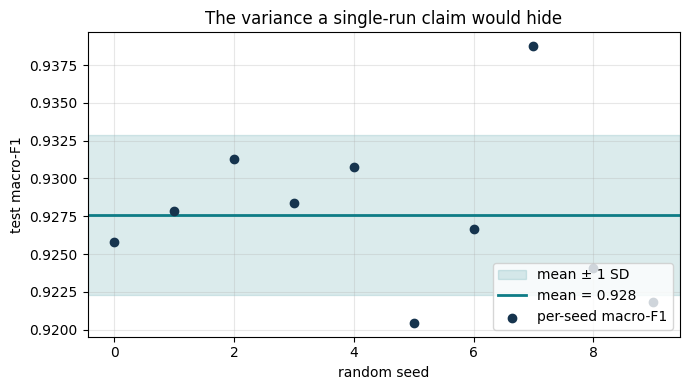

In [4]:
seeds = range(10); f1s = []
for s in seeds:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    m = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LinearSVC(C=0.5, random_state=s)).fit(Xtr, ytr)
    f1s.append(macro_f1(m, Xte, yte))
f1s = np.array(f1s)
print("Per-seed macro-F1:", np.round(f1s, 4))
print(f"Mean ± std : {f1s.mean():.4f} ± {f1s.std(ddof=1):.4f}")
print(f"Min / Max  : {f1s.min():.4f} / {f1s.max():.4f}  (spread = {f1s.max()-f1s.min():.4f})")
plt.figure()
plt.axhspan(f1s.mean()-f1s.std(ddof=1), f1s.mean()+f1s.std(ddof=1), color="#0E7C86", alpha=0.15, label="mean ± 1 SD")
plt.axhline(f1s.mean(), color="#0E7C86", lw=2, label=f"mean = {f1s.mean():.3f}")
plt.scatter(list(seeds), f1s, color="#16344E", zorder=5, label="per-seed macro-F1")
plt.xlabel("random seed"); plt.ylabel("test macro-F1"); plt.title("The variance a single-run claim would hide")
plt.legend(loc="lower right"); plt.tight_layout(); plt.savefig("fig_seed_variance.png", dpi=160); plt.show()

**🧪 Analysis.** Report **mean ± SD over ≥ 5 seeds**. The thesis protocol goes further: each drafting query is generated k times per system with fixed seeds, because LLM generation is stochastic even at low temperature (the gap found in the Deliverable 6 audit).

## Exercise 3 · A proper ablation study
Remove **one component at a time** from the fancy pipeline: bigrams, sublinear term frequency, IDF weighting, and the min_df filter. Mean ± SD over 5 seeds.

In [5]:
CONFIGS = {
    "FULL model": dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True, use_idf=True),
    "- remove bigrams": dict(ngram_range=(1, 1), min_df=2, sublinear_tf=True, use_idf=True),
    "- remove sublinear tf": dict(ngram_range=(1, 2), min_df=2, sublinear_tf=False, use_idf=True),
    "- remove IDF weighting": dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True, use_idf=False),
    "- remove min_df filter": dict(ngram_range=(1, 2), min_df=1, sublinear_tf=True, use_idf=True),
}
def evaluate(cfg, seeds=range(5)):
    sc = []
    for s in seeds:
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
        m = make_pipeline(TfidfVectorizer(**cfg), LinearSVC(C=0.5, random_state=s)).fit(Xtr, ytr)
        sc.append(macro_f1(m, Xte, yte))
    return np.array(sc)
abl_scores = {k: evaluate(v) for k, v in CONFIGS.items()}
full = abl_scores["FULL model"]
abl = pd.DataFrame([(k, v.mean(), v.std(ddof=1), v.mean() - full.mean()) for k, v in abl_scores.items()],
                   columns=["Configuration", "Macro-F1 (mean)", "Std", "Δ vs full"])
print(abl.round(4).to_string(index=False))

         Configuration  Macro-F1 (mean)    Std  Δ vs full
            FULL model           0.9288 0.0023     0.0000
      - remove bigrams           0.9267 0.0028    -0.0021
 - remove sublinear tf           0.9221 0.0034    -0.0067
- remove IDF weighting           0.9207 0.0056    -0.0081
- remove min_df filter           0.9287 0.0027    -0.0001


**🧪 Interpretation.** Components with the most negative Δ do the most work; a Δ inside the noise band is an honest negative result. In the thesis the same logic separates the contribution of retrieval (B0 → B1) from that of the verifiability layer (B1 → B2), with everything else held fixed.

## Exercise 4 · Generate a Model Card
Nine sections (Mitchell et al., 2019) for the **doctoral artefact**, filled honestly: where something is not known yet, it says `UNKNOWN — to investigate`.

In [6]:
# 🛠 CUSTOMIZED FOR THE DOCTORAL RESEARCH — no invented thesis results.
U = "UNKNOWN — to investigate"
model_card = {
 "Model details": {
  "Name / version": "VeriClause-HITL v0.0 — Verifiable, human-in-the-loop clause recommendation assistant (research specification)",
  "Owner / contact": "Jesús Vicente Inca Cárdenas — UNMSM Doctoral Program in Deep Tech, AI & Emerging Technologies",
  "Documentation date": "22 October 2026",
  "Development status": "Pre-implementation Design Science Research specification (Deliverable No. 3). Not yet built, evaluated with experts, or deployed.",
  "Architecture": "Seven planned components: (i) de-identification pipeline; (ii) knowledge base of de-identified precedent clauses and applicable norms (Law No. 26702, SBS Resolution No. 1010-99, circulars), versioned with the validity dates of each provision; (iii) query autocompletion; (iv) hybrid retrieval of precedents and norms; (v) generation with a self-hosted LLM; (vi) verifiability layer that decomposes each candidate clause into propositions, checks support by the cited span and that the cited provision is in force, and withholds unsupported candidates; (vii) human review interface (accept / edit / reject).",
  "Generation model": f"Self-hosted open-weight LLM served on-premise; specific model, version and quantisation: {U} before the formative evaluation.",
  "License": f"{U} — code licence and the licences of the selected LLM and embedding models must be checked before any release.",
 },
 "Intended use": {
  "Primary intended uses": "Advisory recommendation of two or three candidate clauses, each with citations to the supporting precedent clauses and normative provisions, for one bounded clause family within one trust type, inside one SBS-supervised fiduciary institution.",
  "Intended users": "Qualified legal analysts of the host institution, who retain authority over every adopted clause; researchers evaluating the artefact under an approved protocol.",
  "Out-of-scope / misuse": "NOT for autonomous adoption of clauses; legal advice to clients or the public; jurisdictions, clause families or trust types not covered by the knowledge base; credit evaluation or any decision about individuals; regulatory reporting; use as an authoritative source of law; processing identifiable client data on external services; evaluating the performance of individual employees.",
 },
 "Factors": {
  "Relevant groups / conditions": "Clause family and trust type; normative tier of the supporting source (law, regulation, circular, precedent); temporal validity of the cited provision at the reference date; query type (adaptation of a precedent vs. norm-driven drafting); Spanish legal register; analyst experience.",
  "Evaluation factors": "Results will be disaggregated by condition (B0 no retrieval, B1 standard RAG, B2 proposed artefact, B3 current practice), by hallucination type (unsupported, misattributed, contradictory), by normative tier, and by clause subtype where the sample allows.",
 },
 "Metrics": {
  "Primary 1 — Attribution quality": "Citation precision and recall (Gao et al., 2023) plus span-level attributability judged by lawyers under the AIS criterion (Rashkin et al., 2023).",
  "Primary 2 — Hallucination rate": "Proportion of generated propositions that are unsupported, misattributed or contradict the governing framework, reported by type.",
  "Primary 3 — Legal correctness (non-inferiority)": "Expert severity rubric per clause aggregated by maximum severity; share of queries with at least one legally acceptable suggestion, tested against a prespecified margin Δ.",
  "Secondary / process": "Citation faithfulness probe; outdated-source rate; abstention rate; review time and edits relative to B3; accepted, edited and rejected suggestions.",
  "Variation approach": "Each query run k times per system with fixed seeds; mean ± SD across runs; mixed-effects logistic regression with item and run effects; paired bootstrap 95% CIs; Holm–Bonferroni across metric × baseline contrasts; one-sided CI for the non-inferiority margin.",
 },
 "Evaluation data": {
  "Dataset / design": "NOT YET COLLECTED. Drafting queries for one clause family, evaluated under B0–B3 on a dated, frozen snapshot of the knowledge base; number of queries and k fixed by an a priori power analysis recorded in the preregistration.",
  "Gold standard": "Two to three external lawyers with at least five years in trust or financial-regulatory practice, written guideline, Krippendorff’s α ≥ 0.67 (≥ 0.80 preferred), adjudication by a senior expert; annotators blind to condition; the researcher does not annotate.",
  "Independence rule": "Queries and gold passages are created without access to the artefact’s segmentation, metadata or outputs (lesson from the Deliverable No. 6 audit).",
  "Preprocessing": f"De-identification or pseudonymisation of all contract text before any processing; exact pipeline and residual re-identification test: {U} before data collection.",
 },
 "Training data": {
  "Datasets": f"No fine-tuning is planned in v0.0: knowledge enters through retrieval, not training. The pre-training data of the selected LLM are those of its provider: {U}.",
  "Knowledge base (non-parametric)": "De-identified precedent clauses from the institution’s typology-specific templates and executed contracts, and the applicable normative corpus retrieved from the SBS portal and SPIJ with recorded consultation dates.",
  "Leakage control": "Prompts, thresholds and retrieval settings are frozen before the summative evaluation; evaluation queries are never used for tuning. Any later adaptation would be versioned as a new DSR iteration.",
 },
 "Quantitative analyses": {
  "Overall results": "NO THESIS RESULTS YET — no claim about attribution, hallucination or legal correctness of the artefact is made in this deliverable.",
  "Proxy component evidence": "Deliverable No. 5 evaluated a clause-type recogniser on public LEDGAR contracts (English, 20 types, 3,000 clauses): macro-F1 92.39% ± 0.11% across 7 seeds, against 0.48% for a majority baseline. This is evidence about a candidate component on a public proxy, not about the artefact.",
  "Disaggregated results": "Per-class F1 of the proxy recogniser (seed 42): from 0.98+ (Governing Laws, Severability, Counterparts) down to 0.81 (Terminations) and 0.68 (General). For the thesis, results will be reported per condition, per hallucination type and per normative tier, never as a single pooled score.",
 },
 "Ethical considerations": {
  "Risks": "Disclosure of information protected by banking secrecy (Law No. 26702, art. 140) or personal data (Law No. 29733; Supreme Decree No. 016-2024-JUS); fluent but unsupported or outdated clauses; automation bias and over-reliance; attributable but legally incorrect clauses; unclear accountability for adopted text; insider bias of a researcher who leads technology in the host institution.",
  "Mitigations": "On-premise, self-hosted processing; de-identification and data minimisation; advisory-only design with the analyst’s decision required; verifiability layer with in-force check and abstention; separate legal-correctness rubric; stopping rule for leaks or highest-severity recommendations; external blind annotators; preregistration; voluntary adoption of the high-risk safeguards of Supreme Decree No. 115-2025-PCM (arts. 31.1, 31.4 and 32).",
  "Human agency principle": "Outputs are suggestions with visible sources, never decisions. No clause enters a contract without a qualified legal officer’s decision.",
 },
 "Caveats and recommendations": {
  "Caveats": "Research-stage specification only. Verifiability is necessary but not sufficient for a trustworthy clause. No accuracy, safety, generalisability or external validity has been established; transfer beyond one institution is analytical, not statistical.",
  "Recommendations": "Before the summative evaluation freeze: LLM and model versions, knowledge-base snapshot, prompts, thresholds, clause family, gold-standard guideline, margin Δ, sample size, analysis plan and environment; read every parameter from one configuration file and log it with each run (Deliverable No. 5 scaffold).",
 },
}

def render(card, title):
    lines = [f"# {title}", ""]
    for section, fields in card.items():
        lines.append(f"## {section}")
        lines += [f"- **{k}:** {v}" for k, v in fields.items()]
        lines.append("")
    return "\n".join(lines)
card_md = render(model_card, "Model Card — VeriClause-HITL v0.0")
Path("model_card.md").write_text(card_md, encoding="utf-8")
print(card_md[:1500], "...")
print("\n✅ Saved model_card.md —", len(model_card), "sections; no thesis metrics fabricated.")

# Model Card — VeriClause-HITL v0.0

## Model details
- **Name / version:** VeriClause-HITL v0.0 — Verifiable, human-in-the-loop clause recommendation assistant (research specification)
- **Owner / contact:** Jesús Vicente Inca Cárdenas — UNMSM Doctoral Program in Deep Tech, AI & Emerging Technologies
- **Documentation date:** 22 October 2026
- **Development status:** Pre-implementation Design Science Research specification (Deliverable No. 3). Not yet built, evaluated with experts, or deployed.
- **Architecture:** Seven planned components: (i) de-identification pipeline; (ii) knowledge base of de-identified precedent clauses and applicable norms (Law No. 26702, SBS Resolution No. 1010-99, circulars), versioned with the validity dates of each provision; (iii) query autocompletion; (iv) hybrid retrieval of precedents and norms; (v) generation with a self-hosted LLM; (vi) verifiability layer that decomposes each candidate clause into propositions, checks support by the cited span and tha

**🧪 Integrity note.** The only quantitative evidence in the card is the Deliverable 5 proxy component (clause-type recognition on public LEDGAR), labelled as such. The artefact’s own attribution, hallucination and correctness results do not exist yet.

## Exercise 5 · Generate a Datasheet
Seven lifecycle sections (Gebru et al., 2021) for the **planned evaluation dataset**.

In [7]:
datasheet = {
 "Motivation": {
  "Purpose": "Create a traceable evaluation dataset to test whether a verifiable clause-recommendation artefact improves attribution and reduces hallucination relative to B0, B1 and current practice, without loss of legal correctness.",
  "Created by / funded by": f"Planned doctoral dataset led by Jesús Vicente Inca Cárdenas (UNMSM) in one SBS-supervised fiduciary institution, under written institutional authorisation. Funding: self-funded doctoral research with possible in-kind institutional support; {U}.",
 },
 "Composition": {
  "What instances represent": "One instance is a drafting query linked to its candidate clauses from each condition (B0–B3), their citations, and the gold annotations of attribution, hallucination type and legal severity.",
  "Linked components": "(A) de-identified precedent clauses; (B) normative provisions with identifiers and validity dates; (C) drafting queries; (D) system outputs and run metadata (seed, model version, snapshot); (E) gold annotations and adjudication records.",
  "Sample vs population": f"One clause family within one trust type in one institution. NOT representative of all Peruvian fiduciary contracts or institutions. Number of queries: {U} until the power analysis.",
  "Current status / missingness": "NO DATA COLLECTED YET. Field dictionary, missing-data rules and corpus size will be reported only in aggregate after de-identification.",
 },
 "Collection process": {
  "How collected": "Precedent clauses extracted from the institution’s templates and executed contracts and de-identified on-premise; norms retrieved from the SBS normative portal and SPIJ with consultation dates; queries elicited with the legal area; system outputs logged by the prototype; annotations produced by external lawyers with a written guideline.",
  "Experimental structure": "Same queries under B0, B1 and B2 (same base model) with k seeded runs each, plus B3 clauses drafted by legal staff under the usual procedure.",
  "Consent / ethics": "Begins only after ethics approval at UNMSM and written institutional authorisation; informed consent and confidentiality agreements for annotators, panel members and participating analysts.",
  "Timeframe": f"Months 19–24 of the doctoral plan; exact dates: {U}.",
 },
 "Preprocessing / cleaning / labeling": {
  "Steps": "De-identification before any processing; separation of identifiers under restricted access; versioning of the normative corpus with validity dates; dated snapshot frozen for evaluation; annotation of attribution spans, hallucination type and severity; agreement reported with Krippendorff’s α; documented adjudication.",
  "Leakage control": "Gold passages and queries created without access to the artefact’s segmentation or outputs; annotators blind to condition; no evaluation query used for tuning.",
  "Raw data available": "Raw contract text, client data and pre-de-identification records will NOT be released and will not leave the institution’s controlled environment.",
 },
 "Uses": {
  "Appropriate uses": "Doctoral evaluation of the artefact; reproducibility audit of the comparison; analysis of attribution, hallucination and correctness failure modes; refinement of design principles.",
  "Should NOT be used for": "Training commercial or unrelated models; re-identification of clients, counterparties or trusts; legal advice; assessment or ranking of individual employees (B3 data describe practice, not people); profiling; claims about other institutions or clause families.",
 },
 "Distribution": {
  "How distributed": "Shareable after review: schema, annotation guideline, synthetic examples, aggregate results and the public normative corpus with consultation dates. Contract-derived data stay access-controlled inside the institution.",
  "License / restrictions": f"{U} — to be aligned with the institutional authorisation, banking secrecy, data-protection law and consent terms.",
 },
 "Maintenance": {
  "Maintainer": "Doctoral researcher under UNMSM governance and the host institution’s data-protection policies.",
  "Versioning": "Snapshots versioned with DVC and MD5 hashes, runs logged in MLflow, normative updates recorded with validity dates (scaffold of Deliverable No. 5).",
  "Retention / deletion": f"Retention period, storage location, access revocation and deletion schedule: {U} before data collection.",
 },
}

ds_md = render(datasheet, "Datasheet — Fiduciary Clause Recommendation Evaluation Dataset v0.0")
Path("datasheet.md").write_text(ds_md, encoding="utf-8")
print(ds_md[:1200], "...")
print("\n✅ Saved datasheet.md —", len(datasheet), "sections.")

# Datasheet — Fiduciary Clause Recommendation Evaluation Dataset v0.0

## Motivation
- **Purpose:** Create a traceable evaluation dataset to test whether a verifiable clause-recommendation artefact improves attribution and reduces hallucination relative to B0, B1 and current practice, without loss of legal correctness.
- **Created by / funded by:** Planned doctoral dataset led by Jesús Vicente Inca Cárdenas (UNMSM) in one SBS-supervised fiduciary institution, under written institutional authorisation. Funding: self-funded doctoral research with possible in-kind institutional support; UNKNOWN — to investigate.

## Composition
- **What instances represent:** One instance is a drafting query linked to its candidate clauses from each condition (B0–B3), their citations, and the gold annotations of attribution, hallucination type and legal severity.
- **Linked components:** (A) de-identified precedent clauses; (B) normative provisions with identifiers and validity dates; (C) drafting queries

## Exercise 6 · Documentation scorecard (self-audit)
Checks honesty and completeness, not accuracy.

In [8]:
def score_documentation(model_card, datasheet):
    flat = lambda card: " ".join(f"{k} {v}".lower() for f in card.values() for k, v in f.items())
    mc, ds = flat(model_card), flat(datasheet)
    checks = [
        ("Model Card has all 9 sections", len(model_card) == 9),
        ("Datasheet has all 7 sections", len(datasheet) == 7),
        ("Intended misuse / out-of-scope stated", "not for" in mc or "out-of-scope" in mc),
        ("Performance reported with variation (± / std / seeds)", "±" in mc or "std" in mc or "seed" in mc),
        ("Metrics disaggregated (per-class / per-group)", "per-class" in mc or "disaggreg" in mc),
        ("Dataset 'should NOT be used for' stated", "should not be used" in ds),
        ("Collection process described", "how collected" in " ".join(datasheet["Collection process"]).lower()),
        ("Gaps flagged honestly ('unknown')", "unknown" in mc and "unknown" in ds),
    ]
    for label, ok in checks: print(("✅ " if ok else "❌ ") + label)
    passed = sum(ok for _, ok in checks)
    print(f"\nScore: {passed}/{len(checks)}")
    lines = ["# Documentation Scorecard", "", f"**Score: {passed}/{len(checks)}**", ""] + [f"- {'✅' if ok else '❌'} {l}" for l, ok in checks]
    lines += ["", "> Evaluates documentation completeness and transparency, not empirical performance."]
    Path("documentation_scorecard.md").write_text("\n".join(lines), encoding="utf-8")
    return passed, len(checks)
passed, total = score_documentation(model_card, datasheet)

✅ Model Card has all 9 sections
✅ Datasheet has all 7 sections
✅ Intended misuse / out-of-scope stated
✅ Performance reported with variation (± / std / seeds)
✅ Metrics disaggregated (per-class / per-group)
✅ Dataset 'should NOT be used for' stated
✅ Collection process described
✅ Gaps flagged honestly ('unknown')

Score: 8/8


---
# Part B · Extension exercises — from a table to a defensible claim

## Exercise 7 · Is the gain real? Significance & confidence intervals
(a) Paired comparison over seeds (t-test and Wilcoxon); (b) exact McNemar test on one held-out set; (c) bootstrap 95% CI.

In [9]:
from scipy import stats
N_SEEDS = 10; fancy_f1, base_f1 = [], []
for s in range(N_SEEDS):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    f = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LinearSVC(C=0.5, random_state=s)).fit(Xtr, ytr)
    b = make_pipeline(TfidfVectorizer(), LogisticRegression(C=best_C, max_iter=5000, random_state=s)).fit(Xtr, ytr)
    fancy_f1.append(macro_f1(f, Xte, yte)); base_f1.append(macro_f1(b, Xte, yte))
fancy_f1, base_f1 = np.array(fancy_f1), np.array(base_f1); diff = fancy_f1 - base_f1
print(f"fancy    : {fancy_f1.mean():.4f} ± {fancy_f1.std(ddof=1):.4f}")
print(f"baseline : {base_f1.mean():.4f} ± {base_f1.std(ddof=1):.4f}")
print(f"mean paired difference: {diff.mean():+.4f}")
t_stat, t_p = stats.ttest_rel(fancy_f1, base_f1); w_stat, w_p = stats.wilcoxon(fancy_f1, base_f1)
print(f"Paired t-test : t={t_stat:+.3f}, p={t_p:.4f}")
print(f"Wilcoxon      : W={w_stat:.1f}, p={w_p:.4f}")
print("Caveat: overlapping splits make seeds correlated, so these p-values are optimistic (Nadeau & Bengio, 2003).")

fancy    : 0.9276 ± 0.0053
baseline : 0.9154 ± 0.0053
mean paired difference: +0.0122
Paired t-test : t=+7.480, p=0.0000
Wilcoxon      : W=0.0, p=0.0020
Caveat: overlapping splits make seeds correlated, so these p-values are optimistic (Nadeau & Bengio, 2003).


In [10]:
pf, pb = fancy.predict(X_test), strong.predict(X_test)
b_only = int(np.sum((pf == y_test) & (pb != y_test))); c_only = int(np.sum((pf != y_test) & (pb == y_test)))
n_dis = b_only + c_only
mcnemar_p = 1.0 if n_dis == 0 else float(stats.binomtest(min(b_only, c_only), n_dis, 0.5).pvalue)
print(f"fancy right & baseline wrong: {b_only} | baseline right & fancy wrong: {c_only} | exact McNemar p = {mcnemar_p:.4f}")
rng = np.random.default_rng(RANDOM_STATE); n = len(y_test); idx = np.arange(n)
boot = []
for _ in range(2000):
    i = rng.integers(0, n, n); boot.append(f1_score(y_test[i], pf[i], average="macro") - f1_score(y_test[i], pb[i], average="macro"))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Paired bootstrap 95% CI of the macro-F1 difference on the test set: [{lo:+.4f}, {hi:+.4f}]")

fancy right & baseline wrong: 20 | baseline right & fancy wrong: 13 | exact McNemar p = 0.2962
Paired bootstrap 95% CI of the macro-F1 difference on the test set: [-0.0067, +0.0232]


**🧪 Analysis.** Attach a test or a CI before writing “outperforms”. The thesis uses exactly this family of tools at the query level: paired bootstrap CIs and mixed-effects models, with Holm correction — and never a pooled test over aggregated metrics, the flaw found in the Deliverable 6 audit.

## Exercise 8 · Compute-matched comparison
Sweep the feature budget of the fancy model (`max_features`, a proxy for capacity) and compare it with the tuned baseline at full budget.

  max_features=   250: 0.8602 ± 0.0143  <- at or below tuned baseline
  max_features=   500: 0.8893 ± 0.0134  <- at or below tuned baseline
  max_features=  1000: 0.9128 ± 0.0090  <- at or below tuned baseline
  max_features=  2000: 0.9214 ± 0.0039
  max_features=  5000: 0.9247 ± 0.0037
  max_features= 20000: 0.9289 ± 0.0022
  max_features= 50000: 0.9288 ± 0.0023
Tuned baseline (full vocabulary): 0.9154


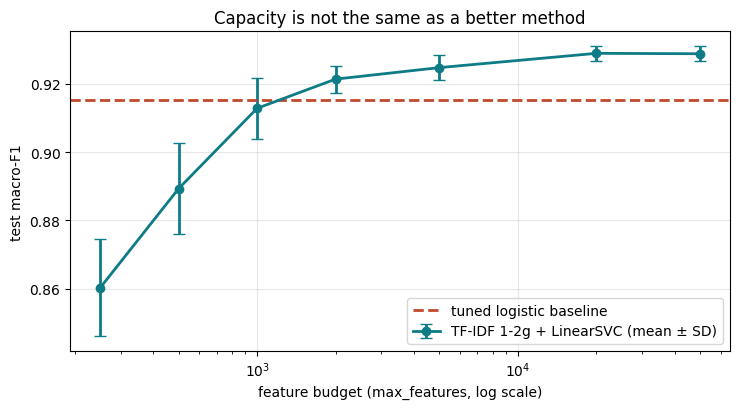

In [11]:
budgets = [250, 500, 1000, 2000, 5000, 20000, 50000]; means, stds = [], []
for nb in budgets:
    sc = []
    for s in range(5):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
        m = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=nb), LinearSVC(C=0.5, random_state=s)).fit(Xtr, ytr)
        sc.append(macro_f1(m, Xte, yte))
    means.append(np.mean(sc)); stds.append(np.std(sc, ddof=1))
means, stds = np.array(means), np.array(stds); baseline_mean = base_f1.mean()
for nb, m_, s_ in zip(budgets, means, stds):
    print(f"  max_features={nb:6d}: {m_:.4f} ± {s_:.4f}" + ("  <- at or below tuned baseline" if m_ <= baseline_mean else ""))
print(f"Tuned baseline (full vocabulary): {baseline_mean:.4f}")
plt.figure(figsize=(7.5, 4.2))
plt.errorbar(budgets, means, yerr=stds, marker="o", capsize=4, lw=2, color="#0E7C86", label="TF-IDF 1-2g + LinearSVC (mean ± SD)")
plt.axhline(baseline_mean, ls="--", lw=2, color="#C0492B", label="tuned logistic baseline")
plt.xscale("log"); plt.xlabel("feature budget (max_features, log scale)"); plt.ylabel("test macro-F1")
plt.title("Capacity is not the same as a better method"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("fig_compute_matched.png", dpi=160); plt.show()

**🧪 Analysis.** Report the budget of every method. In the thesis, B0, B1 and B2 share the same base model, the same knowledge-base snapshot and the same retrieval depth, so a gain cannot be bought with extra capacity or extra context.

## Exercise 9 · The data-leakage trap
Pure-noise features with 20 clause-type labels: select the “best” features on all rows (leaky) versus inside each fold (honest).

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif
rng = np.random.default_rng(RANDOM_STATE)
X_noise = rng.normal(size=(len(y), 5000)); chance = pd.Series(y).value_counts(normalize=True).max()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
leaky = cross_val_score(LogisticRegression(max_iter=3000), SelectKBest(f_classif, k=50).fit_transform(X_noise, y), y, cv=cv)
honest = cross_val_score(make_pipeline(SelectKBest(f_classif, k=50), LogisticRegression(max_iter=3000)), X_noise, y, cv=cv)
print(f"No-information accuracy (1/20 types)   : {chance:.4f}")
print(f"LEAKY  (select on all rows, then CV)   : {leaky.mean():.4f} ± {leaky.std(ddof=1):.4f}")
print(f"HONEST (select inside each fold)       : {honest.mean():.4f} ± {honest.std(ddof=1):.4f}")
print(f"Phantom accuracy created by leakage    : {leaky.mean()-honest.mean():+.4f}")

No-information accuracy (1/20 types)   : 0.0500
LEAKY  (select on all rows, then CV)   : 0.0937 ± 0.0084
HONEST (select inside each fold)       : 0.0440 ± 0.0058
Phantom accuracy created by leakage    : +0.0497


**🧪 Analysis.** Anything learned from data must be fitted inside the training fold. In a RAG evaluation the equivalent leak is subtler: building the evaluation questions from the system’s own chunks, or tuning prompts and thresholds on the evaluation queries. The Datasheet therefore requires queries and gold passages to be created without access to the artefact’s segmentation or outputs.

## Exercise 10 · Ablation with error bars + multiple comparisons

         Configuration  Macro-F1 (mean)    Std  Δ vs full  Paired p (vs full)  Bonferroni sig.
      - remove bigrams           0.9267 0.0028    -0.0021              0.0071             True
 - remove sublinear tf           0.9221 0.0034    -0.0067              0.0097             True
- remove IDF weighting           0.9207 0.0056    -0.0081              0.0128            False
- remove min_df filter           0.9287 0.0027    -0.0001              0.9485            False

With 4 comparisons at alpha=0.05, P(>=1 false positive) = 18.5%; Bonferroni alpha = 0.0125


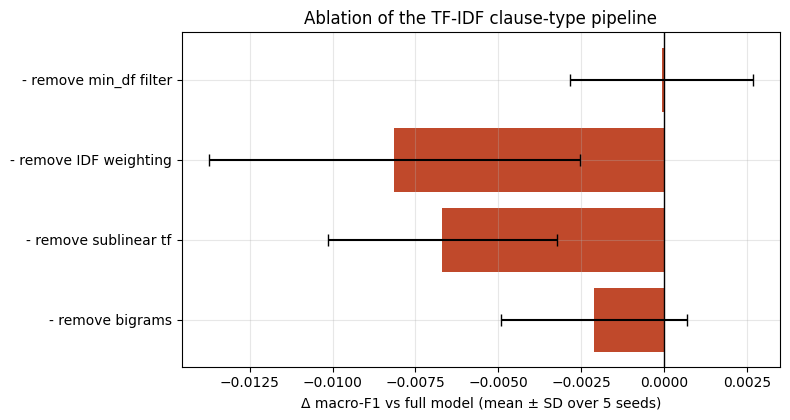

In [13]:
plot_df = abl[abl["Configuration"] != "FULL model"].copy()
plot_df["Paired p (vs full)"] = [stats.ttest_rel(abl_scores[c], full).pvalue for c in plot_df["Configuration"]]
k = len(plot_df); plot_df["Bonferroni sig."] = plot_df["Paired p (vs full)"] < 0.05 / k
print(plot_df.round(4).to_string(index=False))
plt.figure(figsize=(8, 0.7 * k + 1.5))
plt.barh(plot_df["Configuration"], plot_df["Δ vs full"], xerr=plot_df["Std"], capsize=4,
         color=["#C0492B" if d < 0 else "#0E7C86" for d in plot_df["Δ vs full"]])
plt.axvline(0, color="black", lw=1); plt.xlabel("Δ macro-F1 vs full model (mean ± SD over 5 seeds)")
plt.title("Ablation of the TF-IDF clause-type pipeline"); plt.tight_layout()
plt.savefig("fig_ablation_errorbars.png", dpi=160); plt.show()
print(f"\nWith {k} comparisons at alpha=0.05, P(>=1 false positive) = {1-(1-0.05)**k:.1%}; Bonferroni alpha = {0.05/k:.4f}")

**🧪 Analysis.** Error bars turn a ranking into a statement of evidence, and the multiple-comparison correction is why the thesis preregisters its primary contrasts (B2 vs B1 on attribution and hallucination; non-inferiority on correctness) and applies Holm–Bonferroni to the rest.

## Exercise 11 · Regulatory documentation crosswalk
Educational gap analysis against **EU AI Act Annex IV** (as in class) and against the regulation that actually applies to the thesis: **Peru’s Law No. 31814 and its Regulation, Supreme Decree No. 115-2025-PCM**, whose high-risk safeguards the protocol adopts voluntarily.

In [14]:
crosswalk = pd.DataFrame([
 ("EU AI Act IV(1) General description: purpose, provider, version", "Model details; Intended use", "COVERED", "-"),
 ("EU AI Act IV(2) Development process: data, design choices, methods", "Training data; Evaluation data; Metrics", "PARTIAL", "LLM and version, knowledge-base snapshot and evaluation data not yet fixed."),
 ("EU AI Act IV(3) Monitoring, functioning & control; accuracy by group", "Factors; Quantitative analyses", "PARTIAL", "Disaggregation planned; no artefact results yet."),
 ("EU AI Act IV(4) Appropriateness of performance metrics", "Metrics", "COVERED", "Primary, secondary and process metrics justified in the protocol."),
 ("EU AI Act IV(5) Risk management: foreseeable risks & mitigations", "Ethical considerations", "COVERED", "-"),
 ("EU AI Act IV(8) Post-market monitoring / known limitations", "Caveats and recommendations", "PARTIAL", "No deployment yet; monitoring plan pending."),
 ("Peru DS 115-2025-PCM art. 22.2 Risk classification", "Intended use; Out-of-scope", "PARTIAL", "Provisionally acceptable-risk; formal consultation (art. 24.2) if uncertain."),
 ("Peru DS 115-2025-PCM art. 31.1 Record of operating principles, data sources, impacts", "Model details; Training data; Datasheet", "PARTIAL", "Will be complete once components and corpus are frozen."),
 ("Peru DS 115-2025-PCM art. 31.4 Human oversight: stop, correct, override", "Intended use; Human agency principle", "COVERED", "-"),
 ("Peru DS 115-2025-PCM art. 32 Impact assessment", "Ethical considerations", "GAP", "Documented AI impact assessment scheduled for months 13–18."),
], columns=["Element", "Maps to", "Status", "Needs attention"])
print(crosswalk.to_string(index=False))
md = ["# Regulatory Documentation Crosswalk (educational)", "", "_Educational gap analysis only; not a conformity assessment._", "",
      "| Element | Maps to | Status | Needs attention |", "|---|---|---|---|"] + [f"| {a} | {b} | {c} | {d} |" for a, b, c, d in crosswalk.values]
Path("regulatory_crosswalk.md").write_text("\n".join(md), encoding="utf-8")
print("\n", crosswalk["Status"].value_counts().to_dict())

                                                                             Element                                 Maps to  Status                                                              Needs attention
                     EU AI Act IV(1) General description: purpose, provider, version             Model details; Intended use COVERED                                                                            -
                  EU AI Act IV(2) Development process: data, design choices, methods Training data; Evaluation data; Metrics PARTIAL  LLM and version, knowledge-base snapshot and evaluation data not yet fixed.
                EU AI Act IV(3) Monitoring, functioning & control; accuracy by group          Factors; Quantitative analyses PARTIAL                             Disaggregation planned; no artefact results yet.
                              EU AI Act IV(4) Appropriateness of performance metrics                                 Metrics COVERED            Primary, seconda

**🧪 Analysis.** Every PARTIAL or GAP row is a sentence that cannot yet be written for a regulator — and a task with a date in the protocol timeline.

## Exercise 12 · Bundle the reproducibility report

In [15]:
import sys, sklearn, scipy, zipfile, json
from datetime import datetime, timezone
summary = {"ex1_fancy": f1_fancy, "ex1_weak": f1_weak, "ex1_strong": f1_strong, "best_C": best_C,
           "ex2_mean": f1s.mean(), "ex2_sd": f1s.std(ddof=1), "ex2_min": f1s.min(), "ex2_max": f1s.max(),
           "ex7_fancy": fancy_f1.mean(), "ex7_fancy_sd": fancy_f1.std(ddof=1), "ex7_base": base_f1.mean(), "ex7_base_sd": base_f1.std(ddof=1),
           "ex7_diff": diff.mean(), "ex7_t": t_stat, "ex7_tp": t_p, "ex7_wp": w_p, "mcnemar_b": b_only, "mcnemar_c": c_only, "mcnemar_p": mcnemar_p,
           "boot_lo": lo, "boot_hi": hi, "ex9_chance": chance, "ex9_leaky": leaky.mean(), "ex9_honest": honest.mean(),
           "ablation": abl.round(5).to_dict("records"), "ablation_p": plot_df[["Configuration", "Paired p (vs full)"]].round(5).to_dict("records"),
           "compute": dict(zip(map(str, budgets), np.round(means, 5).tolist())), "scorecard": f"{passed}/{total}"}
Path("results_summary.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
report = [
 "# Reproducibility Report — Session 7 / Deliverable 7", f"_Generated {datetime.now(timezone.utc):%Y-%m-%d %H:%M} UTC_", "",
 "## Environment", f"- Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | scipy {scipy.__version__}",
 f"- RANDOM_STATE = {RANDOM_STATE}; data = LEDGAR subset from Deliverable 5, MD5 {hashlib.md5(DATA.read_bytes()).hexdigest()}", "",
 "## Doctoral artefact status", "- VeriClause-HITL v0.0 — research specification; no thesis results claimed.",
 "- LLM, knowledge-base snapshot, prompts and gold standard not yet frozen.", f"- Documentation scorecard: {passed}/{total}.", "",
 "## Integrity boundary", "- Exercises 1–3 and 7–10 use public LEDGAR clauses as a proxy; they are course demonstrations, not evidence about the artefact.", "",
 "## Artifacts", "- model_card.md, datasheet.md, documentation_scorecard.md, regulatory_crosswalk.md, results_summary.json",
 "- fig_seed_variance.png, fig_compute_matched.png, fig_ablation_errorbars.png (proxy demonstrations)"]
Path("REPRODUCIBILITY_REPORT.md").write_text("\n".join(report), encoding="utf-8")
files = ["model_card.md", "datasheet.md", "documentation_scorecard.md", "regulatory_crosswalk.md", "REPRODUCIBILITY_REPORT.md",
         "results_summary.json", "fig_seed_variance.png", "fig_compute_matched.png", "fig_ablation_errorbars.png"]
with zipfile.ZipFile("Session7_deliverable_Inca.zip", "w") as z:
    for f in files: z.write(f)
print("\n".join(report)); print("\n✅ Bundle: Session7_deliverable_Inca.zip")

# Reproducibility Report — Session 7 / Deliverable 7
_Generated 2026-10-22 19:45 UTC_

## Environment
- Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | scipy 1.17.1
- RANDOM_STATE = 42; data = LEDGAR subset from Deliverable 5, MD5 bc995ef9bacb814a07d06dbecad47ad0

## Doctoral artefact status
- VeriClause-HITL v0.0 — research specification; no thesis results claimed.
- LLM, knowledge-base snapshot, prompts and gold standard not yet frozen.
- Documentation scorecard: 8/8.

## Integrity boundary
- Exercises 1–3 and 7–10 use public LEDGAR clauses as a proxy; they are course demonstrations, not evidence about the artefact.

## Artifacts
- model_card.md, datasheet.md, documentation_scorecard.md, regulatory_crosswalk.md, results_summary.json
- fig_seed_variance.png, fig_compute_matched.png, fig_ablation_errorbars.png (proxy demonstrations)

✅ Bundle: Session7_deliverable_Inca.zip
